# EDA 05: độ phủ theo giờ và khoảng trống

Dữ liệu có mặt vào những giờ nào, ngày nào, ở bao nhiêu user; khi GPS ngừng ghi thì ngừng lúc nào, bao lâu, hai đầu có gần nhau không. Notebook không chọn trước khung giờ hay định nghĩa "qua đêm".

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 12 | Dữ liệu phủ những giờ nào, ngày nào, ở bao nhiêu user? | Khung giờ home/office (A10), dữ liệu tối thiểu (A11) |
| 13 | Khoảng trống xảy ra lúc nào, dài bao lâu, hai đầu có gần nhau không? | Nguồn phụ để suy ra home/office (A12) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục được đánh số liên tục 1–13 xuyên các notebook; xem bảng ở README.

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 04 mục 10. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.dev_users()   # nhóm dev (D17); đặt None để chạy mọi user (không dùng để chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['coverage'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
gaps = R.gaps
print(f"{len(users)} user, {len(files):,} file")

[20/122] đã đọc tới user 031 (4 giây)
[40/122] đã đọc tới user 058 (6 giây)
[60/122] đã đọc tới user 091 (8 giây)
[80/122] đã đọc tới user 117 (9 giây)
[100/122] đã đọc tới user 147 (12 giây)
[120/122] đã đọc tới user 177 (15 giây)
[122/122] đã đọc tới user 179 (15 giây)
122 user, 13,022 file


## 12. Độ phủ theo thứ và giờ

**Câu hỏi:** dữ liệu có mặt vào những giờ nào trong ngày, ngày nào trong tuần, và ở bao nhiêu user? Notebook không chọn trước khung giờ nào là "đêm" hay "giờ làm việc"; việc đó thuộc bước gán home/office.

**Đơn vị đo:** *phút có dữ liệu*, tức một phút (giờ địa phương) có ít nhất một điểm GPS. Cách này không cần ngưỡng khoảng trống, và không thiên về user ghi dày: user ghi mỗi giây hay mỗi 5 giây đều tính là 1 phút.

- `data_hours`: tổng số phút có dữ liệu của user, đổi ra giờ.
- `cov_wd_hour` (theo user): số phút có dữ liệu theo thứ × giờ.
- `days_hour` (theo user): số ngày khác nhau có dữ liệu trong mỗi giờ của ngày.


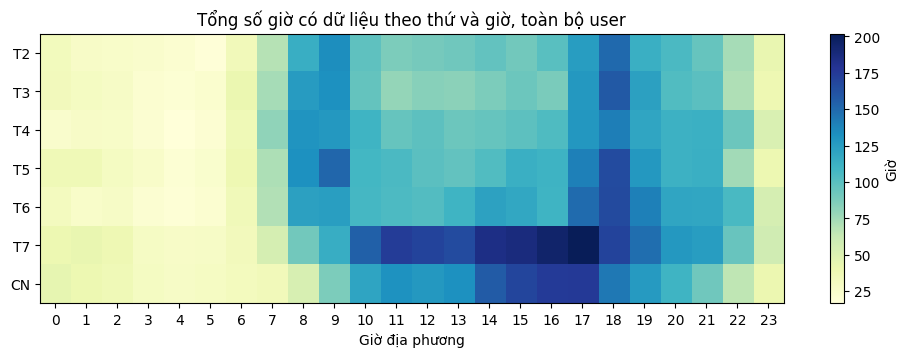

Tổng: 14,722 giờ có dữ liệu
  Thứ Hai đến thứ Sáu: 67.2%  |  Thứ Bảy, Chủ nhật: 32.8%


giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
% số giờ có dữ liệu,1.7,1.6,1.4,1.2,1.0,1.1,1.7,3.1,5.2,5.9,5.4,5.3,5.2,5.2,5.7,5.9,6.0,7.1,7.4,6.1,5.4,5.1,3.9,2.2


In [2]:
cov = A["cov_wd_hour"].sum(axis=0) / 60      # giờ có dữ liệu, [thứ, giờ]
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(cov, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(7)); ax.set_yticklabels(WEEKDAYS)
ax.set_xticks(range(24)); ax.set_xlabel("Giờ địa phương")
ax.set_title("Tổng số giờ có dữ liệu theo thứ và giờ, toàn bộ user")
plt.colorbar(im, ax=ax, label="Giờ")
plt.show()
tot = cov.sum()
print(f"Tổng: {tot:,.0f} giờ có dữ liệu")
print(f"  Thứ Hai đến thứ Sáu: {cov[:5].sum() / tot * 100:.1f}%  |  Thứ Bảy, Chủ nhật: {cov[5:].sum() / tot * 100:.1f}%")
pd.Series(cov.sum(axis=0) / tot * 100, index=pd.Index(range(24), name="giờ"), name="% số giờ có dữ liệu").round(1).to_frame().T


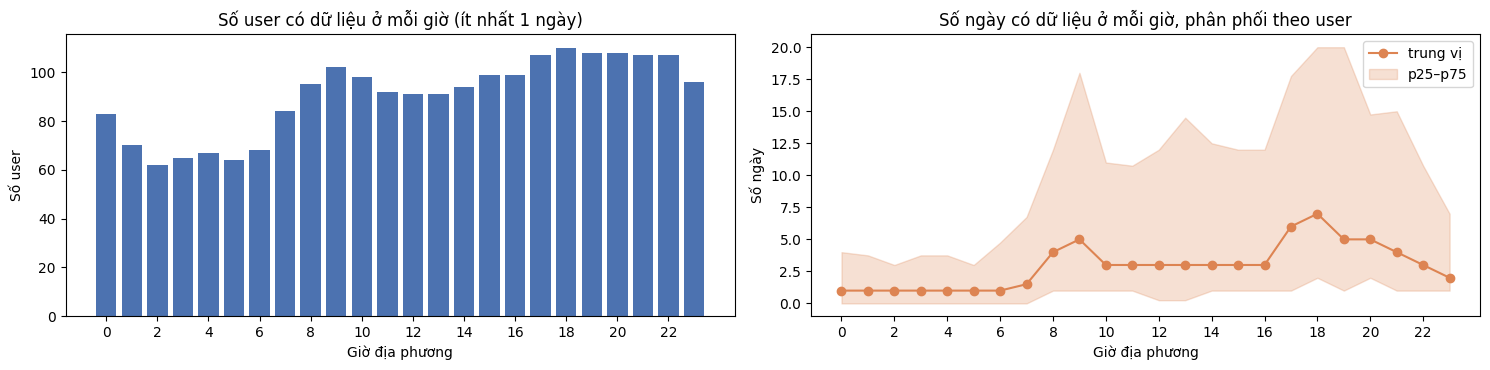

In [3]:
dh = A["days_hour"]          # [user, giờ]: số ngày có dữ liệu trong giờ đó
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].bar(range(24), (dh > 0).sum(axis=0), color="#4c72b0")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("Giờ địa phương"); axes[0].set_ylabel("Số user")
axes[0].set_title("Số user có dữ liệu ở mỗi giờ (ít nhất 1 ngày)")
q = np.percentile(dh, [25, 50, 75], axis=0)
axes[1].plot(range(24), q[1], marker="o", color="#dd8452", label="trung vị")
axes[1].fill_between(range(24), q[0], q[2], color="#dd8452", alpha=0.25, label="p25–p75")
axes[1].set_xticks(range(0, 24, 2)); axes[1].set_xlabel("Giờ địa phương"); axes[1].set_ylabel("Số ngày")
axes[1].set_title("Số ngày có dữ liệu ở mỗi giờ, phân phối theo user")
axes[1].legend()
plt.tight_layout()
plt.show()


Số user có ít nhất *k* ngày có dữ liệu ở mỗi giờ địa phương. Các mức *k* chỉ là mốc mô tả; ngưỡng dữ liệu tối thiểu được chọn ở bước gán home/office.


In [4]:
levels = [1, 3, 5, 10, 20]
pd.DataFrame({f"≥ {k} ngày": (dh >= k).sum(axis=0) for k in levels},
             index=pd.Index(range(24), name="giờ")).T


giờ,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
≥ 1 ngày,83,70,62,65,67,64,68,84,95,102,98,92,91,91,94,99,99,107,110,108,108,107,107,96
≥ 3 ngày,45,37,36,37,36,35,38,55,72,77,70,67,68,67,63,69,75,79,84,79,78,71,73,60
≥ 5 ngày,29,28,28,25,24,26,31,47,57,63,54,53,50,51,49,51,57,65,72,63,62,59,57,47
≥ 10 ngày,19,18,18,15,11,17,17,24,41,42,36,33,38,38,36,34,37,47,53,51,44,41,34,26
≥ 20 ngày,10,6,6,3,3,5,10,16,25,30,24,23,24,22,21,20,21,27,32,32,23,20,21,16


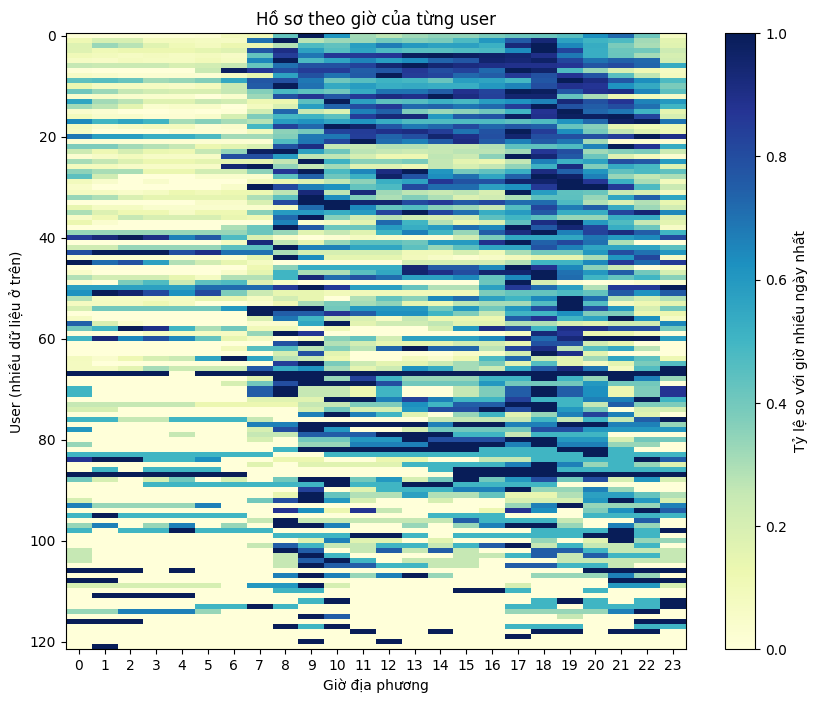

In [5]:
# Hồ sơ theo giờ của từng user: số ngày có dữ liệu ở mỗi giờ, chuẩn hóa theo giờ cao nhất của user đó
prof = dh / np.maximum(dh.max(axis=1, keepdims=True), 1)
order = np.argsort(-A["cov_wd_hour"].sum(axis=(1, 2)))
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(prof[order], aspect="auto", cmap="YlGnBu", interpolation="nearest")
ax.set_xticks(range(24)); ax.set_xlabel("Giờ địa phương")
ax.set_ylabel("User (nhiều dữ liệu ở trên)")
ax.set_title("Hồ sơ theo giờ của từng user")
plt.colorbar(im, ax=ax, label="Tỷ lệ so với giờ nhiều ngày nhất")
plt.show()


**Ngày thường và cuối tuần.** Cùng cách đo, tách riêng ngày thường (thứ Hai đến thứ Sáu) và cuối tuần (thứ Bảy, Chủ nhật), vì nhịp sinh hoạt hai loại ngày thường khác nhau. Số ngày cuối tuần chỉ bằng khoảng 2/5 số ngày thường, nên so sánh *hình dạng* theo giờ hơn là độ lớn.


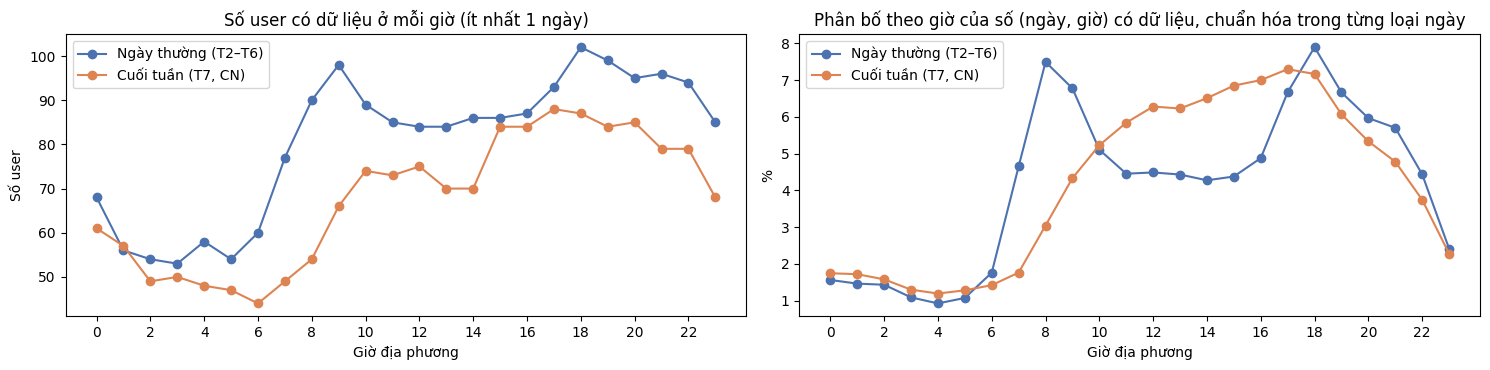

giờ                            0   1   2   3   4   5   6   7   8   9   10  11  \
Ngày thường (T2–T6) ≥ 1 ngày   68  56  54  53  58  54  60  77  90  98  89  85   
                    ≥ 3 ngày   38  31  28  28  25  27  31  51  67  68  58  53   
                    ≥ 5 ngày   25  19  23  18  18  21  23  37  52  58  43  39   
                    ≥ 10 ngày  13  12  11   9   5  10  15  21  34  41  26  25   
Cuối tuần (T7, CN)  ≥ 1 ngày   61  57  49  50  48  47  44  49  54  66  74  73   
                    ≥ 3 ngày   22  19  20  19  19  19  23  21  29  38  40  46   
                    ≥ 5 ngày   16  11  13  10   9  11  10  11  19  24  31  29   
                    ≥ 10 ngày   4   4   4   3   2   2   5   4   9  13  17  17   

giờ                            12  13  14  15  16  17   18  19  20  21  22  23  
Ngày thường (T2–T6) ≥ 1 ngày   84  84  86  86  87  93  102  99  95  96  94  85  
                    ≥ 3 ngày   56  54  54  56  56  70   77  69  73  66  63  53  
                    ≥ 5 ngày   42  44  41  40  43  52   63  60  55  57  48  36  
                    ≥ 10 ngày  28  29  25  26  29  34   42  41  37  34  26  20  
Cuối tuần (T7, CN)  ≥ 1 ngày   75  70  70  84  84  88   87  84  85  79  79  68  
                    ≥ 3 ngày   46  45  47  43  49  57   54  50  46  35  36  28  
                    ≥ 5 ngày   31  38  36  31  37  42   41  37  30  26  26  16  
                    ≥ 10 ngày  17  17  16  19  19  19   21  16  17  16  12   7

In [6]:
dw = A["days_hour_wk"]        # [user, 0 = ngày thường / 1 = cuối tuần, giờ]
kinds = ["Ngày thường (T2–T6)", "Cuối tuần (T7, CN)"]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for k, (lab, col) in enumerate(zip(kinds, ["#4c72b0", "#dd8452"])):
    axes[0].plot(range(24), (dw[:, k] > 0).sum(axis=0), marker="o", color=col, label=lab)
    share = dw[:, k].sum(axis=0) / max(dw[:, k].sum(), 1) * 100
    axes[1].plot(range(24), share, marker="o", color=col, label=lab)
axes[0].set_ylabel("Số user"); axes[0].set_title("Số user có dữ liệu ở mỗi giờ (ít nhất 1 ngày)")
axes[1].set_ylabel("%"); axes[1].set_title("Phân bố theo giờ của số (ngày, giờ) có dữ liệu, chuẩn hóa trong từng loại ngày")
for ax in axes:
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Giờ địa phương"); ax.legend()
plt.tight_layout()
plt.show()

levels = [1, 3, 5, 10]
pd.concat({lab: pd.DataFrame({f"≥ {k} ngày": (dw[:, j] >= k).sum(axis=0) for k in levels},
                             index=pd.Index(range(24), name="giờ")).T
           for j, lab in enumerate(kinds)})


## 13. Khoảng trống: xảy ra lúc nào, dài bao lâu, hai đầu có gần nhau không

**Câu hỏi:** khi GPS ngừng ghi, khoảng trống thường bắt đầu và kết thúc lúc mấy giờ (địa phương), kéo dài bao lâu, và điểm trước khi ngừng với điểm sau khi ghi lại cách nhau bao xa? Nếu có một nhóm khoảng trống bắt đầu buổi tối, kết thúc buổi sáng và hai đầu gần nhau, đó là dấu hiệu user tắt máy ở cùng một chỗ. Notebook không định nghĩa trước thế nào là "qua đêm".

`gaps.csv` lưu mọi bước dài hơn mốc nhỏ nhất (`GAP_MARKS_MIN[0]` = 5 phút, dài hơn khoảng lấy mẫu điển hình của mọi user ở mục 4), chỉ xét bước mà hai đầu có timestamp hợp lệ.

- `start_local`, `end_local`: giờ địa phương của điểm trước và sau khoảng trống.
- `gap_h`: độ dài (giờ). `dist_m`: khoảng cách giữa hai đầu (mét).


Khoảng trống > 5 phút: 39,094 ở 121 user


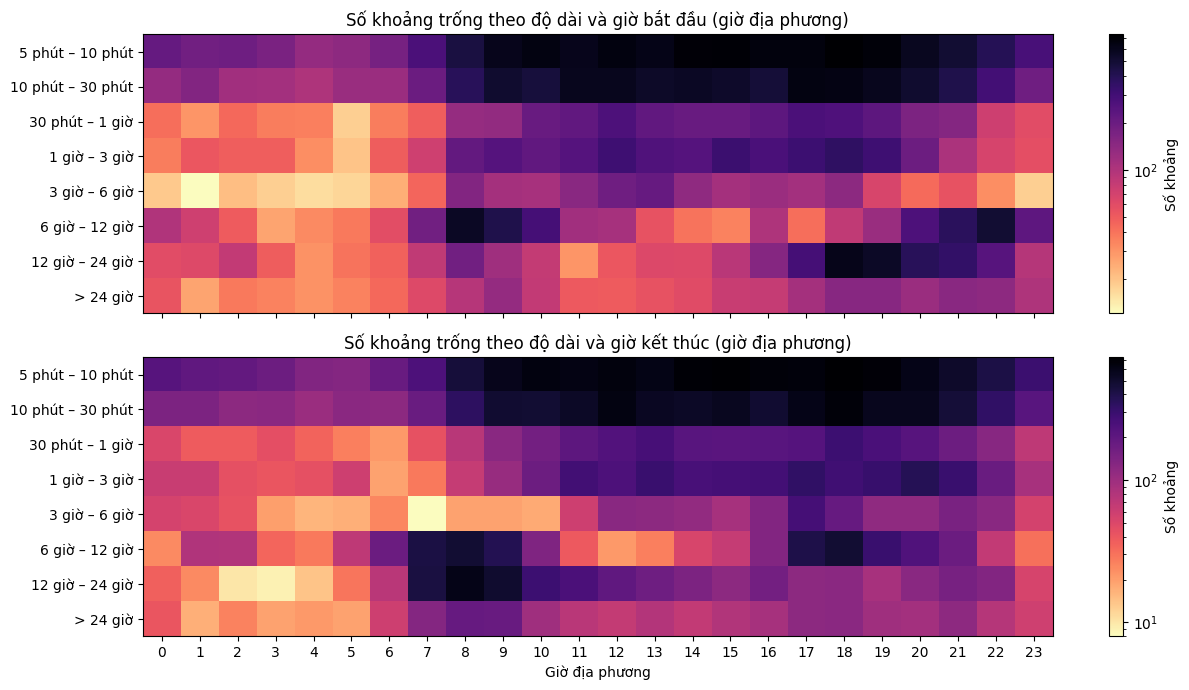

In [7]:
print(f"Khoảng trống > {GAP_MARKS_MIN[0]} phút: {len(gaps):,} ở {gaps['user'].nunique()} user")
gaps["start_hour"] = gaps["start_local"].dt.hour
gaps["end_hour"] = gaps["end_local"].dt.hour
edges = GAP_MARKS_MIN + [np.inf]
dur_labels = [f"{fmt_s(a * 60)} – {fmt_s(b * 60)}" if np.isfinite(b) else f"> {fmt_s(a * 60)}"
              for a, b in zip(edges[:-1], edges[1:])]
gaps["dur"] = pd.cut(gaps["gap_h"] * 60, bins=edges, labels=dur_labels)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, col, title in ((axes[0], "start_hour", "giờ bắt đầu"), (axes[1], "end_hour", "giờ kết thúc")):
    ct = pd.crosstab(gaps["dur"], gaps[col]).reindex(index=dur_labels, columns=range(24), fill_value=0)
    im = ax.imshow(np.ma.masked_equal(ct.to_numpy(), 0), aspect="auto", cmap="magma_r", norm=LogNorm())
    ax.set_yticks(range(len(dur_labels))); ax.set_yticklabels(dur_labels)
    ax.set_title(f"Số khoảng trống theo độ dài và {title} (giờ địa phương)")
    plt.colorbar(im, ax=ax, label="Số khoảng")
axes[1].set_xticks(range(24)); axes[1].set_xlabel("Giờ địa phương")
plt.tight_layout()
plt.show()


Khoảng cách giữa hai đầu khoảng trống, theo độ dài. Các mức 100/200/500/1.000 m chỉ là mốc mô tả.


,số_khoảng,số_user,dist_trung_vị_m,≤ 100 m (%),≤ 200 m (%),≤ 500 m (%),≤ 1000 m (%)
dur,,,,,,,
5 phút – 10 phút,10971,114,28.4,77.9,82.5,87.2,89.7
10 phút – 30 phút,9024,117,29.5,66.7,73.3,79.6,82.2
30 phút – 1 giờ,3343,101,87.5,51.8,63.0,73.7,78.4
1 giờ – 3 giờ,4149,110,146.3,42.4,57.7,73.7,80.9
3 giờ – 6 giờ,1934,95,283.3,27.4,41.7,62.9,73.8
6 giờ – 12 giờ,3920,97,286.3,24.0,39.8,63.9,76.7
12 giờ – 24 giờ,3820,106,442.0,16.6,29.8,53.3,65.5
> 24 giờ,1933,106,1400.9,9.8,18.6,35.7,45.9


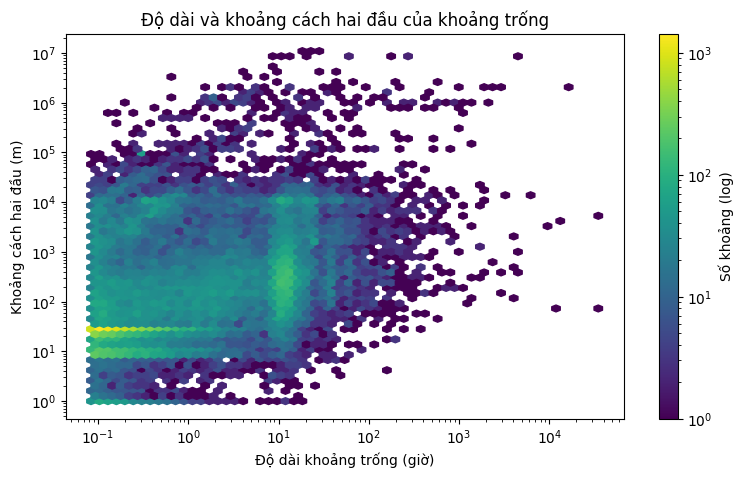

In [8]:
g = gaps.groupby("dur", observed=False)
tb = g.agg(số_khoảng=("dist_m", "size"), số_user=("user", "nunique"), dist_trung_vị_m=("dist_m", "median"))
for r in (100, 200, 500, 1000):
    tb[f"≤ {r} m (%)"] = g["dist_m"].apply(lambda s, r=r: (s <= r).mean() * 100 if len(s) else np.nan)
display(tb.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(gaps["gap_h"], gaps["dist_m"].clip(lower=1), xscale="log", yscale="log",
               gridsize=60, bins="log", cmap="viridis", mincnt=1)
ax.set_xlabel("Độ dài khoảng trống (giờ)"); ax.set_ylabel("Khoảng cách hai đầu (m)")
ax.set_title("Độ dài và khoảng cách hai đầu của khoảng trống")
plt.colorbar(hb, ax=ax, label="Số khoảng (log)")
plt.show()
